In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')
# drive.mount("/content/drive", force_remount=True)

Mounted at /content/drive


In [ ]:
raw_df = pd.read_csv('/content/drive/MyDrive/medical_students_dataset (1).csv')
df = raw_df.copy()
df.head()

,Student ID,Age,Gender,Height,Weight,Blood Type,BMI,Temperature,Heart Rate,Blood Pressure,Cholesterol,Diabetes,Smoking
0,1.0,18.0,Female,161.777924,72.354947,O,27.645835,NaN,95.0,109.0,203.0,No,NaN
1,2.0,NaN,Male,152.069157,47.630941,B,NaN,98.714977,93.0,104.0,163.0,No,No
2,3.0,32.0,Female,182.537664,55.741083,A,16.729017,98.260293,76.0,130.0,216.0,Yes,No
3,NaN,30.0,Male,182.112867,63.332207,B,19.096042,98.839605,99.0,112.0,141.0,No,Yes
4,5.0,23.0,Female,NaN,46.234173,O,NaN,98.480008,95.0,NaN,231.0,No,No


In [ ]:
print(df.columns.tolist())


['Student ID', 'Age', 'Gender', 'Height', 'Weight', 'Blood Type', 'BMI', 'Temperature', 'Heart Rate', 'Blood Pressure', 'Cholesterol', 'Diabetes', 'Smoking']


In [ ]:
df = df.drop(['Student ID'], axis=1)
df.head()

,Age,Gender,Height,Weight,Blood Type,BMI,Temperature,Heart Rate,Blood Pressure,Cholesterol,Diabetes,Smoking
0,18.0,Female,161.777924,72.354947,O,27.645835,NaN,95.0,109.0,203.0,No,NaN
1,NaN,Male,152.069157,47.630941,B,NaN,98.714977,93.0,104.0,163.0,No,No
2,32.0,Female,182.537664,55.741083,A,16.729017,98.260293,76.0,130.0,216.0,Yes,No
3,30.0,Male,182.112867,63.332207,B,19.096042,98.839605,99.0,112.0,141.0,No,Yes
4,23.0,Female,NaN,46.234173,O,NaN,98.480008,95.0,NaN,231.0,No,No


In [ ]:
df.isnull().sum()

,0
Age,20000
Gender,20000
Height,20000
Weight,20000
Blood Type,20000
BMI,20000
Temperature,20000
Heart Rate,20000
Blood Pressure,20000
Cholesterol,20000


In [ ]:
df.head()

,Age,Gender,Height,Weight,Blood Type,BMI,Temperature,Heart Rate,Blood Pressure,Cholesterol,Diabetes,Smoking
0,18.0,Female,161.777924,72.354947,O,27.645835,NaN,95.0,109.0,203.0,No,NaN
1,NaN,Male,152.069157,47.630941,B,NaN,98.714977,93.0,104.0,163.0,No,No
2,32.0,Female,182.537664,55.741083,A,16.729017,98.260293,76.0,130.0,216.0,Yes,No
3,30.0,Male,182.112867,63.332207,B,19.096042,98.839605,99.0,112.0,141.0,No,Yes
4,23.0,Female,NaN,46.234173,O,NaN,98.480008,95.0,NaN,231.0,No,No


In [ ]:
numerical = [
    'Age', 'Height', 'Weight', 'BMI', 'Temperature', 'Heart Rate', 'Blood Pressure', 'Cholesterol'
]
for col in numerical:
    df[col] = df[col].fillna(df[col].mean())

df['Gender'] = df['Gender'].fillna(df['Gender'].mode()[0])
df['Blood Type'] = df['Blood Type'].fillna(df['Blood Type'].mode()[0])
df['Smoking'] = df['Smoking'].fillna(df['Smoking'].mode()[0])

df = pd.get_dummies(df, columns=['Gender', 'Blood Type', 'Smoking'], drop_first=True)


In [ ]:
df.isnull().sum()

,0
Age,0
Height,0
Weight,0
BMI,0
Temperature,0
Heart Rate,0
Blood Pressure,0
Cholesterol,0
Diabetes,20000
Gender_Male,0


In [ ]:
df.tail()

,Age,Height,Weight,BMI,Temperature,Heart Rate,Blood Pressure,Cholesterol,Diabetes,Gender_Male,Blood Type_AB,Blood Type_B,Blood Type_O,Smoking_Yes
199995,24.0,176.503260,95.756997,30.737254,99.170685,65.0,121.0,130.0,No,True,False,True,False,False
199996,29.0,163.917675,45.225194,16.831734,97.865785,62.0,125.0,198.0,No,False,False,True,False,True
199997,34.0,174.947103,99.648914,33.189303,98.768210,60.0,90.0,154.0,NaN,False,False,True,False,False
199998,30.0,156.446944,50.142824,20.486823,98.994212,61.0,106.0,225.0,No,False,False,False,False,False
199999,20.0,153.927409,99.928405,42.175189,98.595817,95.0,133.0,132.0,NaN,False,False,False,True,False


In [ ]:
X = df.drop('Diabetes', axis=1)
y = df['Diabetes']
print(y.value_counts())
print(y.value_counts(normalize=True))

Diabetes
No     161986
Yes     18014
Name: count, dtype: int64
Diabetes
No     0.899922
Yes    0.100078
Name: proportion, dtype: float64


In [ ]:
print(X.dtypes)

Age               float64
Height            float64
Weight            float64
BMI               float64
Temperature       float64
Heart Rate        float64
Blood Pressure    float64
Cholesterol       float64
Gender_Male          bool
Blood Type_AB        bool
Blood Type_B         bool
Blood Type_O         bool
Smoking_Yes          bool
dtype: object


In [ ]:
bool_cols = X.select_dtypes(include='bool').columns
X[bool_cols] = X[bool_cols].astype(float)

In [ ]:
print(X.dtypes)

Age               float64
Height            float64
Weight            float64
BMI               float64
Temperature       float64
Heart Rate        float64
Blood Pressure    float64
Cholesterol       float64
Gender_Male       float64
Blood Type_AB     float64
Blood Type_B      float64
Blood Type_O      float64
Smoking_Yes       float64
dtype: object


In [ ]:
for col in X.columns:
    non_numeric = X[col][~X[col].apply(lambda x: isinstance(x, (int, float)))]
    if not non_numeric.empty:
        print(f"Non-numeric values in '{col}':")
        print(non_numeric.unique())
y = y.map({'No': 0, 'Yes': 1})
print(y.dtype)
X = X.apply(pd.to_numeric, errors='coerce')
X = X.fillna(X.mean())
print(y.isnull().sum())


float64
20000


In [ ]:
print(df['Diabetes'].isnull().sum())
df = df.dropna(subset=['Diabetes'])
X = df.drop('Diabetes', axis=1)
y = df['Diabetes'].map({'No': 0, 'Yes': 1})


20000


In [ ]:
print(y.isnull().sum())
print(y.value_counts())

0
Diabetes
0    161986
1     18014
Name: count, dtype: int64


0 - 160000
1 -  18000

In [ ]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)

In [ ]:
print(y_resampled.value_counts())

Diabetes
0    161986
1    161986
Name: count, dtype: int64


In [ ]:
from sklearn.ensemble import RandomForestClassifier

In [ ]:
rf = RandomForestClassifier(random_state=42)
rf.fit(X_resampled, y_resampled)

RandomForestClassifier(random_state=42)

In [ ]:
importances = rf.feature_importances_
features = X.columns

feature_df = pd.DataFrame({
    'Feature': features,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

print(feature_df)
feat_imp = pd.DataFrame({"Feature": X.columns, "Importance": importances})

           Feature  Importance
0              Age    0.116225
7      Cholesterol    0.095234
5       Heart Rate    0.094812
6   Blood Pressure    0.094383
1           Height    0.093336
2           Weight    0.091182
4      Temperature    0.090458
3              BMI    0.089792
10    Blood Type_B    0.068298
11    Blood Type_O    0.056095
9    Blood Type_AB    0.055852
8      Gender_Male    0.039281
12     Smoking_Yes    0.015052


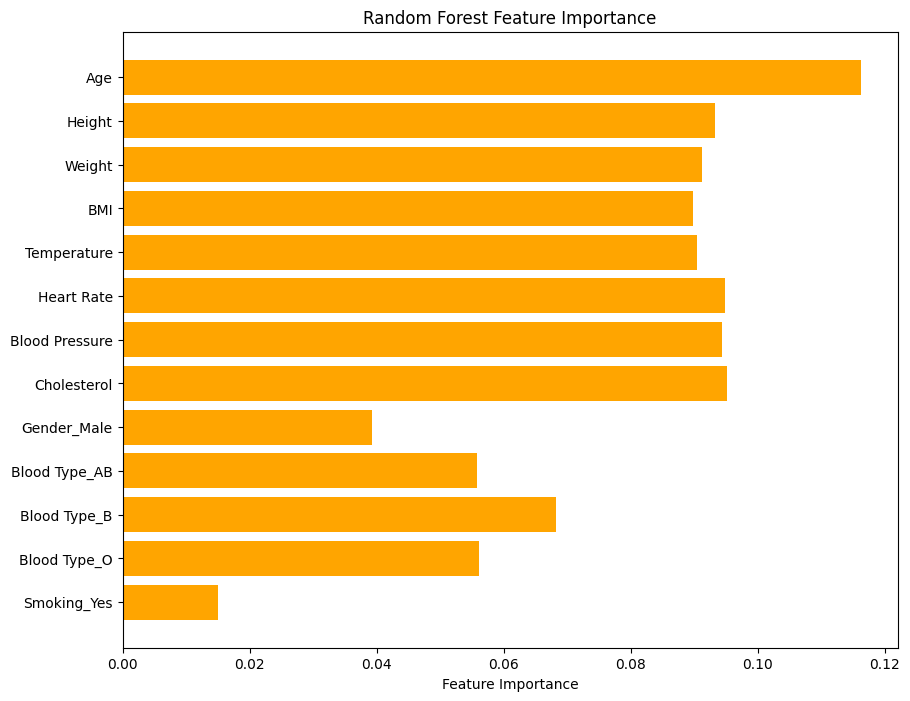

In [ ]:
plt.figure(figsize=(10, 8))
plt.barh(feat_imp['Feature'], feat_imp['Importance'], color='orange')
plt.xlabel('Feature Importance')
plt.title('Random Forest Feature Importance')
plt.gca().invert_yaxis()
plt.show()

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier

models = {
    'Random Forest': RandomForestClassifier(random_state=42),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'KNN': KNeighborsClassifier(),
    'XGBoost': XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
}


In [ ]:
from sklearn.model_selection import train_test_split


X_train, X_test, y_train, y_test = train_test_split(X_resampled, y_resampled, test_size=0.3, random_state=42)

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:183: UserWarning: [17:11:05] WARNING: /workspace/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


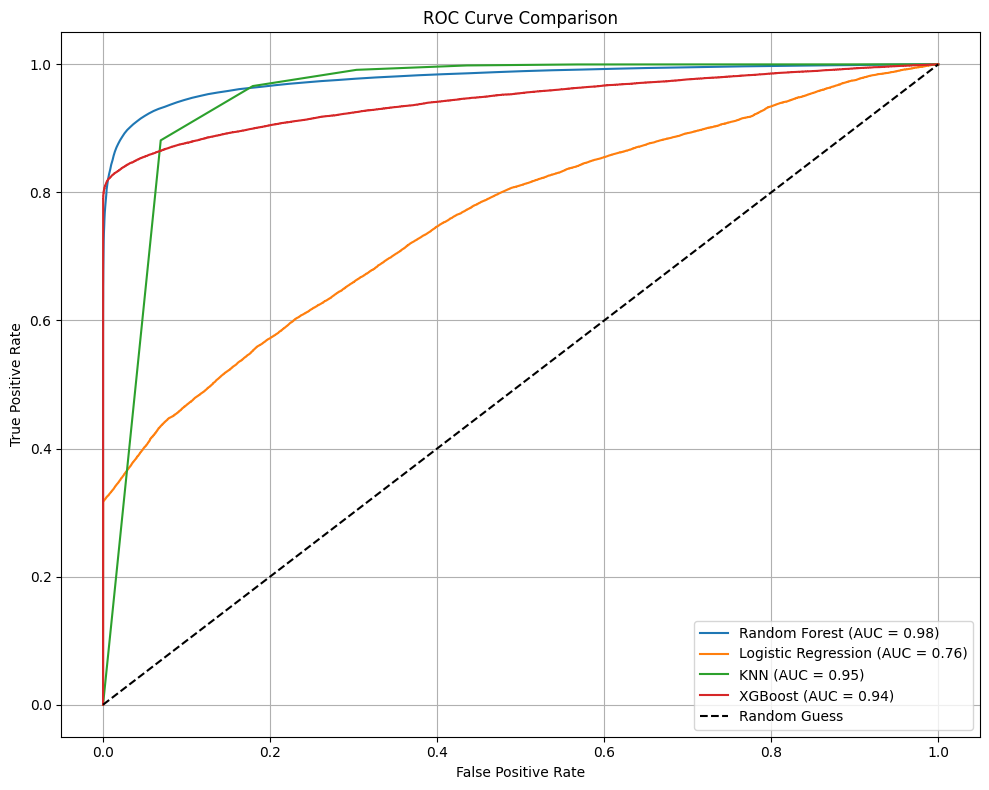

In [ ]:
from sklearn.metrics import roc_curve, auc
from sklearn.model_selection import train_test_split


X_train, X_test, y_train, y_test = train_test_split(X_resampled, y_resampled, test_size=0.3, random_state=42)

plt.figure(figsize=(10,8))

for name, model in models.items():
    model.fit(X_train, y_train)
    y_proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend(loc='lower right')
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

Random Forest Classifier

In [ ]:
model = RandomForestClassifier(n_estimators=200, max_depth=None, random_state=42)
model.fit(X_train, y_train)

RandomForestClassifier(n_estimators=200, random_state=42)

tp - fp
fn - tn

In [ ]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_proba))

[[47256  1478]
 [ 4638 43820]]
              precision    recall  f1-score   support

           0       0.91      0.97      0.94     48734
           1       0.97      0.90      0.93     48458

    accuracy                           0.94     97192
   macro avg       0.94      0.94      0.94     97192
weighted avg       0.94      0.94      0.94     97192

ROC-AUC: 0.9441608961413197


KNN

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

In [ ]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

KNeighborsClassifier()

In [ ]:
y_pred = knn.predict(X_test)
y_proba = knn.predict_proba(X_test)[:, 1]

In [ ]:
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))
print("ROC-AUC Score:", roc_auc_score(y_test, y_proba))

[[33944 14790]
 [  415 48043]]
              precision    recall  f1-score   support

           0       0.99      0.70      0.82     48734
           1       0.76      0.99      0.86     48458

    accuracy                           0.84     97192
   macro avg       0.88      0.84      0.84     97192
weighted avg       0.88      0.84      0.84     97192

ROC-AUC Score: 0.949481686276292


Neural Network

In [ ]:
import tensorflow as tf
from tensorflow.keras import Input
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

NameError: name 'X_train' is not defined

In [ ]:
def plot_history(history):
  fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
  ax1.plot(history.history['loss'], label='loss')
  ax1.plot(history.history['val_loss'], label='val_loss')
  ax1.set_xlabel('Epoch')
  ax1.set_ylabel('Binary crossentropy')
  ax1.grid(True)

  ax2.plot(history.history['accuracy'], label='accuracy')
  ax2.plot(history.history['val_accuracy'], label='val_accuracy')
  ax2.set_xlabel('Epoch')
  ax2.set_ylabel('Accuracy')
  ax2.grid(True)

  plt.show()

In [ ]:
from sklearn.utils import class_weight

In [ ]:
def train_model(X_train, Y_train, num_nodes, dropout_prob, lr, batch_size, epochs):
  class_weights_array = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(Y_train),
    y=Y_train
  )
  class_weights = dict(enumerate(class_weights_array))
  early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
  )
  nn_model = Sequential([
      Input(shape=(X_train.shape[1],)),
      Dense(num_nodes, activation='relu'),
      Dropout(dropout_prob),
      Dense(num_nodes, activation='relu'),
      Dropout(dropout_prob),
      Dense(1, activation='sigmoid')
  ])

  nn_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr), loss='binary_crossentropy', metrics=['accuracy'])
  history = nn_model.fit(
    X_train, Y_train, epochs=epochs, batch_size=batch_size, validation_split=0.2, callbacks=[early_stop], class_weight=class_weights, verbose=0
  )

  return nn_model, history

In [ ]:
least_val_loss = float('inf')
least_loss_model = None
epochs = 100
for num_nodes in [16, 32, 64]:
  for dropout_prob in [0, 0.2]:
    for lr in [0.01, 0.005, 0.001]:
      for batch_size in [32, 64, 128]:
        print(f"{num_nodes} nodes, dropout {dropout_prob}, lr {lr}, batch_size {batch_size}")
        model, history = train_model(X_train, y_train, num_nodes, dropout_prob, lr, batch_size, epochs)
        plot_history(history)
        val_loss = model.evaluate(X_test, y_test)[0]
        if val_loss < least_val_loss:
          least_val_loss = val_loss
          least_loss_model = model

16 nodes, dropout 0, lr 0.01, batch_size 32


KeyboardInterrupt: 

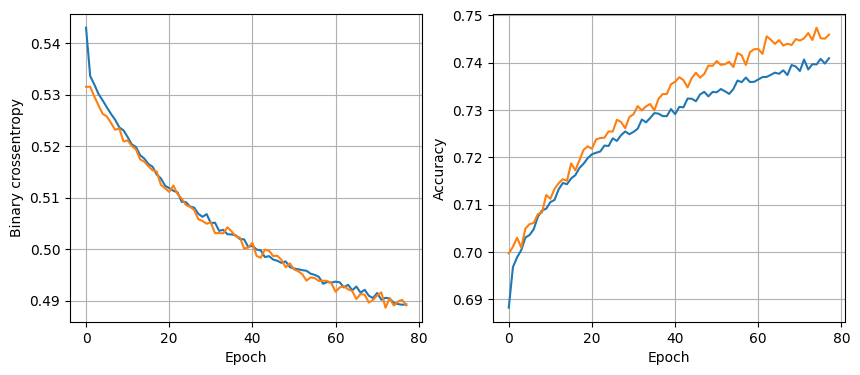

In [ ]:
model, history = train_model(X_train_scaled, y_train, 128, 0.2, 0.001, 64, 100)
plot_history(history)

In [ ]:
print("Mean of each feature:", np.mean(X_train, axis=0))
print("Std of each feature:", np.std(X_train, axis=0))

Mean of each feature: Age                26.034555
Height            174.846561
Weight             69.988513
BMI                23.328148
Temperature        98.596908
Heart Rate         79.492704
Blood Pressure    114.554982
Cholesterol       184.611419
Gender_Male         0.651561
Blood Type_AB       0.291031
Blood Type_B        0.419927
Blood Type_O        0.296221
Smoking_Yes         0.238319
dtype: float64
Std of each feature: Age                4.452568
Height            13.636650
Weight            16.380519
BMI                6.638072
Temperature        0.440885
Heart Rate        10.812478
Blood Pressure    13.563786
Cholesterol       35.525242
Gender_Male        0.476476
Blood Type_AB      0.454238
Blood Type_B       0.493547
Blood Type_O       0.456590
Smoking_Yes        0.426055
dtype: float64


In [ ]:
y_pred_proba = model.predict(X_test_scaled).ravel()
y_pred = (y_pred_proba > 0.4).astype(int)

print(classification_report(y_test, y_pred, target_names=['Non-Diabetic', 'Diabetic']))

print(f"ROC-AUC Score: {roc_auc_score(y_test, y_pred_proba):.4f}")

3038/3038 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step
              precision    recall  f1-score   support

Non-Diabetic       0.78      0.64      0.70     48734
    Diabetic       0.69      0.82      0.75     48458

    accuracy                           0.73     97192
   macro avg       0.74      0.73      0.73     97192
weighted avg       0.74      0.73      0.73     97192

ROC-AUC Score: 0.8322


In [ ]:
print(np.unique(y_train))

[0 1]


In [ ]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import seaborn as sns
from sklearn.preprocessing import StandardScaler

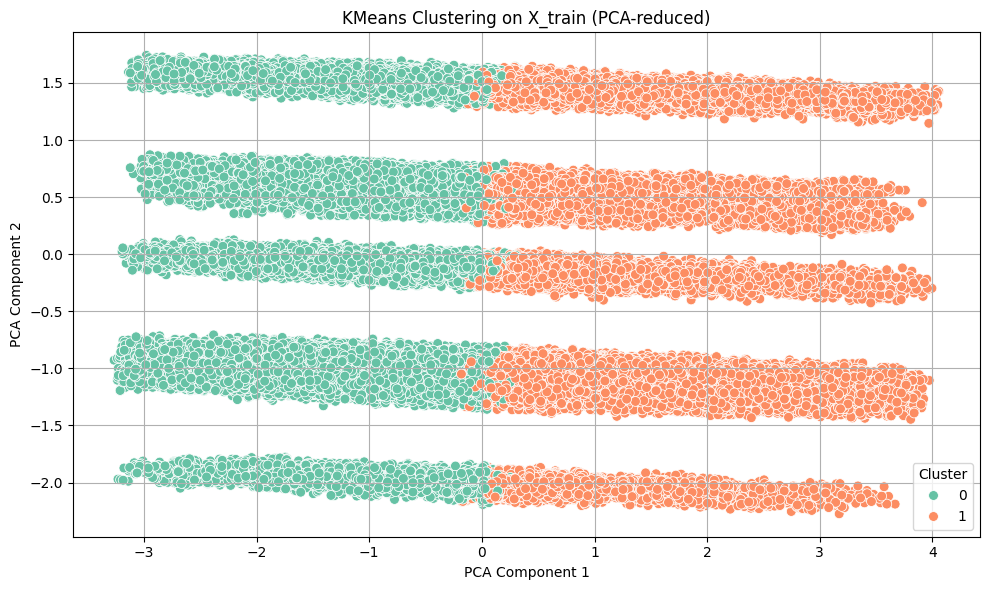

In [ ]:

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train)

kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)


pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(10, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=clusters, palette='Set2', s=50)
plt.title('KMeans Clustering on X_train (PCA-reduced)')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.legend(title='Cluster')
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
y_pred_proba = kmeans.predict(X_test_scaled).ravel()
y_pred = (y_pred_proba > 0.4).astype(int)

print(classification_report(y_test, y_pred, target_names=['Non-Diabetic', 'Diabetic']))

print(f"ROC-AUC Score: {roc_auc_score(y_test, y_pred_proba):.4f}")

NameError: name 'kmeans' is not defined